# 03 — Datasets, Feature Scaling, and Hessian Conditioning

## Purpose

This notebook describes the three binary-classification datasets and examines how feature standardization changes the local curvature of the logistic-regression objective.

The Hessian is evaluated at the zero parameter vector. At this initialization, every observation has predicted probability 0.5, so the logistic curvature weights are all 0.25. The resulting condition numbers are local measurements at this specified point, not global properties of the entire loss surface.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start=None):
    """Find the repository root from the current Jupyter working directory."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "logistic_regression.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Open Jupyter from the repository "
        "folder or one of its subfolders."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import logistic_regression, optimizers

FIGURES_PATH = PROJECT_ROOT / "results" / "figures"
TABLES_PATH = PROJECT_ROOT / "results" / "tables"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

## 1. Load and profile the datasets

Breast Cancer Wisconsin is bundled with scikit-learn. Banknote Authentication and Ionosphere are obtained from OpenML on first use and cached by scikit-learn.

In [2]:
from src.datasets import load_binary_datasets

RANDOM_STATE = 42
TEST_SIZE = 0.20
datasets = load_binary_datasets()

dataset_profile = []
for name, (X_data, y_data) in datasets.items():
    class_counts = np.bincount(y_data, minlength=2)
    dataset_profile.append(
        {
            "Dataset": name,
            "Observations": X_data.shape[0],
            "Original Features": X_data.shape[1],
            "Class 0": int(class_counts[0]),
            "Class 1": int(class_counts[1]),
            "Missing Feature Values": int(np.isnan(X_data).sum()),
        }
    )

dataset_profile_df = pd.DataFrame(dataset_profile)
display(dataset_profile_df)

,Dataset,Observations,Original Features,Class 0,Class 1,Missing Feature Values
0,Breast Cancer,569,30,212,357,0
1,Banknote,1372,4,762,610,0
2,Ionosphere,351,34,225,126,0


## 2. Create matched original and standardized representations

Each dataset receives one stratified 80/20 train/test split with seed 42. Constant features are identified using the training partition only and removed from both partitions. For the standardized condition, the scaler is fitted on training features only and then applied unchanged to the test features.

The two feature conditions therefore use the same observations and the same retained feature columns.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

prepared_datasets = {}
preprocessing_records = []

for name, (X_data, y_data) in datasets.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X_data,
        y_data,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_data,
    )

    keep_mask = np.std(X_train, axis=0) > 1e-10
    removed_indices = np.flatnonzero(~keep_mask)
    X_train_original = X_train[:, keep_mask]
    X_test_original = X_test[:, keep_mask]

    scaler = StandardScaler()
    X_train_standardized = scaler.fit_transform(X_train_original)
    X_test_standardized = scaler.transform(X_test_original)

    prepared_datasets[name] = {
        "original": (X_train_original, X_test_original),
        "standardized": (X_train_standardized, X_test_standardized),
        "y_train": y_train,
        "y_test": y_test,
        "feature_mask": keep_mask,
        "scaler": scaler,
    }
    preprocessing_records.append(
        {
            "Dataset": name,
            "Training Observations": len(y_train),
            "Test Observations": len(y_test),
            "Removed Constant Feature Indices": ", ".join(map(str, removed_indices)) or "None",
            "Retained Features": int(keep_mask.sum()),
        }
    )

preprocessing_df = pd.DataFrame(preprocessing_records)
display(preprocessing_df)

,Dataset,Training Observations,Test Observations,Removed Constant Feature Indices,Retained Features
0,Breast Cancer,455,114,None,30
1,Banknote,1097,275,None,4
2,Ionosphere,280,71,1,33


## 3. Estimate Hessian curvature and condition numbers

With an intercept-augmented design matrix, the Hessian is

$$
 H(\theta)=\frac{1}{m}X^T W X,
 \qquad W_{ii}=p_i(1-p_i).
$$

At _θ=0_, _pᵢ=0.5_, so _W=0.25_. We calculate the eigenvalues and the 2-norm condition number for both feature conditions. The intercept is included in the Hessian in both cases.

In [4]:
conditioning_records = []

for dataset_name, data in prepared_datasets.items():
    for condition in ["original", "standardized"]:
        X_train, _ = data[condition]
        X_bias = logistic_regression.add_intercept(X_train)
        theta_zero = np.zeros(X_bias.shape[1])
        hessian = logistic_regression.compute_hessian(
            X_bias, theta_zero, l2=0.0
        )
        eigenvalues = np.linalg.eigvalsh(hessian)
        condition_number = np.linalg.cond(hessian)

        conditioning_records.append(
            {
                "Dataset": dataset_name,
                "Condition": condition,
                "Minimum Eigenvalue": eigenvalues.min(),
                "Maximum Eigenvalue": eigenvalues.max(),
                "Condition Number": condition_number,
            }
        )

conditioning_df = pd.DataFrame(conditioning_records)
display(conditioning_df.round(6))

original = conditioning_df[conditioning_df["Condition"] == "original"][[
    "Dataset", "Condition Number"
]].rename(columns={"Condition Number": "Original Condition Number"})
standardized = conditioning_df[conditioning_df["Condition"] == "standardized"][[
    "Dataset", "Condition Number"
]].rename(columns={"Condition Number": "Standardized Condition Number"})

scaling_effect_df = original.merge(standardized, on="Dataset")
scaling_effect_df["Condition-Number Reduction (%)"] = (
    100.0 * (1.0 - scaling_effect_df["Standardized Condition Number"] /
             scaling_effect_df["Original Condition Number"])
)
display(scaling_effect_df.round(4))

,Dataset,Condition,Minimum Eigenvalue,Maximum Eigenvalue,Condition Number
0,Breast Cancer,original,0.000000,403396.261110,2.184378e+12
1,Breast Cancer,standardized,0.000032,3.331012,1.038244e+05
2,Banknote,original,0.097829,12.917883,1.320454e+02
3,Banknote,standardized,0.042734,0.541916,1.268123e+01
4,Ionosphere,original,0.004300,1.704614,3.963977e+02
5,Ionosphere,standardized,0.014528,2.228349,1.533813e+02


,Dataset,Original Condition Number,Standardized Condition Number,Condition-Number Reduction (%)
0,Breast Cancer,2.184378e+12,103824.4335,100.0000
1,Banknote,1.320454e+02,12.6812,90.3963
2,Ionosphere,3.963977e+02,153.3813,61.3062


## 4. Visualize the scaling ablation

The condition numbers can span several orders of magnitude, so the vertical axis is logarithmic. A lower condition number indicates a better-conditioned local Hessian under this measurement.

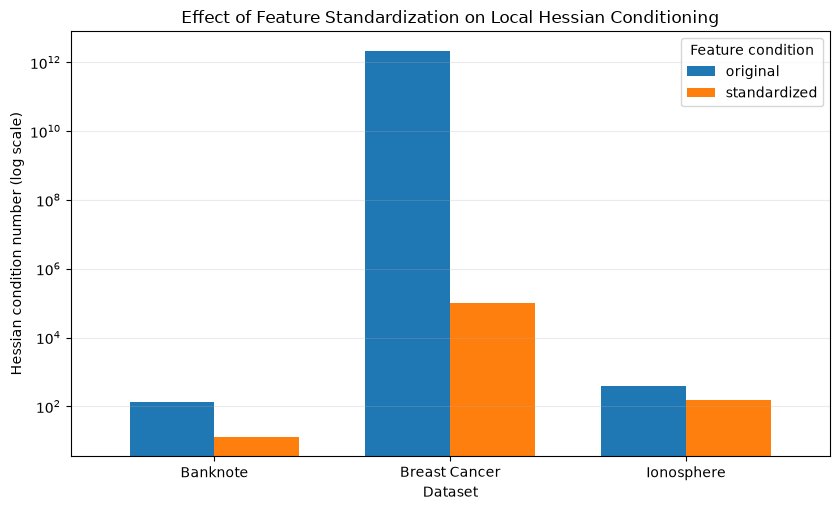

Saved conditioning tables and figure to results/.


In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
plot_data = conditioning_df.pivot(
    index="Dataset", columns="Condition", values="Condition Number"
)
plot_data = plot_data[["original", "standardized"]]
plot_data.plot(kind="bar", ax=ax, logy=True, width=0.72)
ax.set_xlabel("Dataset")
ax.set_ylabel("Hessian condition number (log scale)")
ax.set_title("Effect of Feature Standardization on Local Hessian Conditioning")
ax.legend(title="Feature condition")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(FIGURES_PATH / "hessian_conditioning_by_scaling.png", dpi=300, bbox_inches="tight")
plt.show()

conditioning_df.to_csv(TABLES_PATH / "hessian_conditioning.csv", index=False)
scaling_effect_df.to_csv(TABLES_PATH / "scaling_conditioning_ablation.csv", index=False)
print("Saved conditioning tables and figure to results/.")

## 5. Interpretation and scope

The original and standardized condition numbers are compared dataset by dataset. Standardization rescales feature columns and can improve the relative scaling of directions in parameter space, but it does not guarantee identical improvements on every dataset.

**Scope note:** this notebook uses one fixed stratified split to study Hessian conditioning. Notebook 04 reserves one fixed, untouched stratified test holdout per dataset before tuning. Its repeated evaluation seeds vary the train/validation split within the remaining development pool while reusing that same test holdout. The condition number is evaluated at zero initialization and should be described as a local curvature diagnostic.